# ML Assignment 2 — Online Shoppers Purchasing Intention

**Goal:** Predict whether a website visitor's session ends in a purchase (`Revenue` = True/False) using 5 classifiers — Logistic Regression, Decision Tree, KNN, Naive Bayes, SVM — and compare them with 6 metrics: Accuracy, AUC, Precision, Recall, F1, MCC.

**Dataset:** [UCI — Online Shoppers Purchasing Intention](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset) — 12,330 sessions, 17 features.

## 1. Imports

`pandas`/`numpy` for data handling, `matplotlib`/`seaborn` for plots, `scikit-learn` for preprocessing, models and metrics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42  # fixed seed so results are reproducible every run

pd.set_option("display.max_columns", None)  # show all columns when printing

## 2. Load the dataset

First look at the rows, column types, missing values and the class balance of the target `Revenue`.

In [2]:
df = pd.read_csv("../data/online_shoppers_intention.csv")

print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
# Column types + missing values in one view
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique_values": df.nunique(),
})
summary

,dtype,missing,unique_values
Administrative,int64,0,27
Administrative_Duration,float64,0,3335
Informational,int64,0,17
Informational_Duration,float64,0,1258
ProductRelated,int64,0,311
ProductRelated_Duration,float64,0,9551
BounceRates,float64,0,1872
ExitRates,float64,0,4777
PageValues,float64,0,2704
SpecialDay,float64,0,6


         count  percent
Revenue                
False    10422    84.53
True      1908    15.47


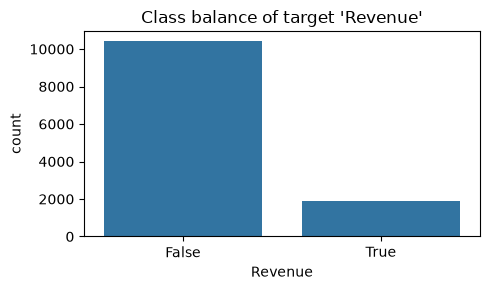

In [4]:
# How balanced is the target? (True = purchase made)
counts = df["Revenue"].value_counts()
percent = df["Revenue"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": percent.round(2)}))

fig, ax = plt.subplots(figsize=(5, 3))
sns.countplot(x="Revenue", data=df, ax=ax)
ax.set_title("Class balance of target 'Revenue'")
plt.tight_layout()
plt.show()

## 3. Preprocessing & train/test split

Models only understand numbers, and distance-based models (KNN, SVM) need all features on a similar scale. So:

1. **Separate features (X) and target (y)** ? `Revenue` becomes 1 (purchase) / 0 (no purchase).
2. **Group the columns**:
   - *Numeric* ? page counts, durations, rates ? will be **standard-scaled** (mean 0, std 1).
   - *Categorical* ? `Month`, `VisitorType`, and the ID-coded columns (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) ? will be **one-hot encoded** (each category becomes its own 0/1 column).
   - *Binary* ? `Weekend` is already 0/1 ? passed through unchanged.
3. **Stratified 80/20 split** ? "stratified" keeps the same 84.5% / 15.5% class ratio in both train and test sets.
4. **Fit the preprocessor on training data only** ? the test set must stay "unseen" (otherwise we leak information and metrics become too optimistic).


In [5]:
# Target: Revenue (True/False) -> 1/0
y = df["Revenue"].astype(int)
X = df.drop(columns=["Revenue"]).copy()
X["Weekend"] = X["Weekend"].astype(int)  # True/False -> 1/0

# Real-valued columns (counts, durations, rates)
numeric_features = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]

# Category columns (some are stored as numbers, but they are just IDs)
categorical_features = [
    "Month", "VisitorType",
    "OperatingSystems", "Browser", "Region", "TrafficType",
]

# Already 0/1 ? no transformation needed
binary_features = ["Weekend"]

print("Total features:", len(numeric_features) + len(categorical_features) + len(binary_features))

Total features: 17


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,          # 80% train / 20% test
    stratify=y,              # keep class ratio identical in both parts
    random_state=RANDOM_STATE,
)

print("Train:", X_train.shape, "| purchase rate:", round(y_train.mean() * 100, 2), "%")
print("Test: ", X_test.shape, "| purchase rate:", round(y_test.mean() * 100, 2), "%")

Train: (9864, 17) | purchase rate: 15.47 %
Test:  (2466, 17) | purchase rate: 15.49 %


In [7]:
# Export the RAW (unprocessed) test rows together with the target column.
# This becomes test_data.csv in the repo ? the file users upload to the Streamlit app.
# The app will load the saved preprocessor and apply it to these raw values.
test_export = X_test.copy()
test_export["Revenue"] = y_test
test_export.to_csv("../test_data.csv", index=False)
print("Saved ../test_data.csv with shape:", test_export.shape)

Saved ../test_data.csv with shape: (2466, 18)


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
        ("bin", "passthrough", binary_features),
    ]
)

# Fit ONLY on the training data, then apply to both sets (no data leakage)
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("Shape before preprocessing:", X_train.shape)
print("Shape after preprocessing: ", X_train_prep.shape)

Shape before preprocessing: (9864, 17)
Shape after preprocessing:  (9864, 74)


## 4. Train the five classifiers

All five models learn from the **same** preprocessed training data and are judged on the **same** unseen test set ? a fair, like-for-like comparison.

| Model | How it thinks (intuition) |
|---|---|
| **Logistic Regression** | Draws a straight boundary; outputs a purchase probability per session. |
| **Decision Tree** | Asks yes/no questions ("PageValues > 5?") and branches until it reaches a decision. |
| **KNN** | Looks at the k most similar sessions and takes a majority vote. |
| **Naive Bayes (Gaussian)** | Uses probability theory, assuming features are independent of each other. |
| **SVM** | Finds the boundary with the widest safety margin between the two classes (`probability=True` so it can also output probabilities for AUC). |

**The six metrics** (all except AUC are computed from the predicted class; AUC uses the predicted probability):
- **Accuracy** ? share of correct predictions. Misleading on imbalanced data (always "no purchase" = 84.5%).
- **AUC** ? ability to rank a true buyer above a non-buyer; 0.5 = coin flip, 1.0 = perfect.
- **Precision** ? of all sessions predicted "will buy", how many actually bought?
- **Recall** ? of all sessions that actually bought, how many did we catch?
- **F1** ? harmonic mean of Precision and Recall (balances the two).
- **MCC** ? correlation between predictions and truth (-1..1); the most honest single number on imbalanced data.


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=11),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
}

In [10]:
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef,
)
import time

results = {}
trained_models = {}

for name, model in models.items():
    start = time.time()
    model.fit(X_train_prep, y_train)              # learn from training data
    y_pred = model.predict(X_test_prep)           # predicted class (0/1) on test data
    y_prob = model.predict_proba(X_test_prep)[:, 1]  # predicted probability of class 1 (for AUC)

    results[name] = {
        "Accuracy":  accuracy_score(y_test, y_pred),
        "AUC":       roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1":        f1_score(y_test, y_pred),
        "MCC":       matthews_corrcoef(y_test, y_pred),
    }
    trained_models[name] = model
    print(f"{name:20s} trained & evaluated in {time.time() - start:.1f}s")

Logistic Regression  trained & evaluated in 0.3s
Decision Tree        trained & evaluated in 0.2s


KNN                  trained & evaluated in 0.7s
Naive Bayes          trained & evaluated in 0.1s


C:\Users\jangraar\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM                  trained & evaluated in 19.9s


In [11]:
# Comparison table ? rows: models, columns: the six required metrics
results_df = pd.DataFrame(results).T.round(4)
results_df

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.8812,0.8830,0.7405,0.3586,0.4832,0.4610
Decision Tree,0.8593,0.7340,0.5452,0.5524,0.5488,0.4654
KNN,0.8743,0.8186,0.6957,0.3351,0.4523,0.4244
Naive Bayes,0.2733,0.7330,0.1727,0.9738,0.2934,0.1292
SVM,0.8873,0.8817,0.7063,0.4660,0.5615,0.5142


## 5. Save the trained models (+ preprocessor)

The repo must contain a `model/` folder with saved trained models for **all five classifiers** plus preprocessing artifacts. The Streamlit app will load these files and predict **without retraining**.

We save with `joblib` (the recommended format for scikit-learn objects). The preprocessor is saved too ? uploaded raw CSVs must pass through the *exact same* scaling/encoding the models were trained with.

Then the crucial check: **reload every file from disk and re-score it** ? proving the saved artifacts reproduce the training-time metrics exactly.

In [12]:
import joblib
from pathlib import Path

model_dir = Path("../model")
model_dir.mkdir(exist_ok=True)

# the preprocessing pipeline is an artifact just like the models
joblib.dump(preprocessor, model_dir / "preprocessor.joblib")

file_names = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree":       "decision_tree.joblib",
    "KNN":                 "knn.joblib",
    "Naive Bayes":         "naive_bayes.joblib",
    "SVM":                 "svm.joblib",
}

for name, fname in file_names.items():
    joblib.dump(trained_models[name], model_dir / fname)

for f in sorted(model_dir.glob("*.joblib")):
    print(f"{f.name:28s} {f.stat().st_size / 1024:9.1f} KB")

decision_tree.joblib             126.0 KB
knn.joblib                      5780.5 KB
logistic_regression.joblib         1.4 KB
naive_bayes.joblib                 3.1 KB
preprocessor.joblib                4.7 KB
svm.joblib                      1634.5 KB


In [13]:
# --- Verification: reload everything from disk and re-score on the raw test set ---
reloaded_preprocessor = joblib.load(model_dir / "preprocessor.joblib")
X_test_check = reloaded_preprocessor.transform(X_test)  # raw test rows -> preprocessed

verify = {}
for name, fname in file_names.items():
    m = joblib.load(model_dir / fname)
    y_pred = m.predict(X_test_check)
    y_prob = m.predict_proba(X_test_check)[:, 1]
    verify[name] = {
        "Accuracy":  accuracy_score(y_test, y_pred),
        "AUC":       roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1":        f1_score(y_test, y_pred),
        "MCC":       matthews_corrcoef(y_test, y_pred),
    }

verify_df = pd.DataFrame(verify).T.round(4)
print("Saved models reproduce training-time metrics exactly:", verify_df.equals(results_df))
verify_df

Saved models reproduce training-time metrics exactly: True


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.8812,0.8830,0.7405,0.3586,0.4832,0.4610
Decision Tree,0.8593,0.7340,0.5452,0.5524,0.5488,0.4654
KNN,0.8743,0.8186,0.6957,0.3351,0.4523,0.4244
Naive Bayes,0.2733,0.7330,0.1727,0.9738,0.2934,0.1292
SVM,0.8873,0.8817,0.7063,0.4660,0.5615,0.5142
